# 06 · Community Classification — stance, themes, factors

Each community is characterised on three axes:
1. **Stance** towards the CJP-led protest (PRO / ANTI / NEUTRAL), predicted for every item by a supervised classifier trained on a manually annotated sample (guidelines in `data/annotations/README.md`), then aggregated to users and communities.
2. **Themes** from a bilingual keyword lexicon (exam integrity, minister accountability, police repression, Wangchuk's fast, opposition politics, conspiracy/funding, …) plus the most distinctive terms per community.
3. **Factors**: account types, follower size, subreddits, activity and shared sources.

In [1]:
import sys; sys.path.insert(0, '.')
from csma_lib import *
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline, make_union
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score, roc_auc_score
setup_plots()
ANN = DATA / 'annotations'
x = load_x_unified(); r = load_reddit_unified()
for c in ['is_bot', 'anonymous', 'removed']:
    r[c] = r[c].astype(str).str.lower().eq('true')
x['is_bot'] = False; x['anonymous'] = False; x['removed'] = False
items = pd.concat([x, r[~r.is_bot]], ignore_index=True)
# Model input. X: post text + quoted text. Reddit: comment/submission text + the thread title (content only). Subreddit tokens would
# raise Reddit macro-F1 by ~0.02 but are deliberately excluded: Reddit communities are venue-based, so a venue-informed stance would make
# the stance-segregation metrics in notebook 08 partly circular.
title = dict(zip(r.loc[r.item_type == 'submission', 'post_id'], r.loc[r.item_type == 'submission', 'text'].str.slice(0, 150)))
is_r = items.platform == 'reddit'
items['text_model'] = (items.text.fillna('') + ' ' + items.quote_text.fillna('')).str.strip()
items.loc[is_r, 'text_model'] = (items.loc[is_r, 'text'].fillna('') + ' [title] ' + items.loc[is_r, 'thread_id'].map(title).fillna('')).str.strip()

## 1. Annotated sample and classifier
Stance labels: PRO = supports the protest / CJP / its demands or attacks the government's handling; ANTI = opposes, mocks or delegitimises the protest / CJP, defends government or police; NEUTRAL = reporting, questions, unclear or mixed. A separate binary label marks **hostile** language (insults, slurs, dehumanising terms, accusations of treason or paid protest).

In [2]:
ax_ = pd.read_csv(ANN / 'x_annotations.csv', dtype={'id': str}); ax_['platform'] = 'x'
ar_ = pd.read_csv(ANN / 'reddit_annotations.csv', dtype={'id': str}) if (ANN / 'reddit_annotations.csv').exists() else pd.DataFrame(columns=ax_.columns)
ar_['platform'] = 'reddit'
ann = pd.concat([ax_, ar_], ignore_index=True).rename(columns={'id': 'post_id'}).drop_duplicates('post_id')
ann = ann.merge(items[['post_id', 'text_model']], on='post_id', how='left')
ann['text_model'] = ann.text_model.fillna(ann.text)
print('annotated items:', len(ann), ann.groupby('platform').stance.value_counts().unstack(fill_value=0).to_dict('index'))
def make_model(C=4.0):
    feats = make_union(TfidfVectorizer(analyzer='word', ngram_range=(1, 2), min_df=2, sublinear_tf=True, lowercase=True),
                       TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), min_df=2, sublinear_tf=True, lowercase=True, max_features=60000))
    return make_pipeline(feats, LogisticRegression(C=C, max_iter=3000, class_weight='balanced'))
cv = StratifiedKFold(5, shuffle=True, random_state=7)
# Second feature view: multilingual sentence embeddings (paraphrase-multilingual-MiniLM-L12-v2, runs on CPU, cached on disk)
import hashlib, os
from sklearn.preprocessing import StandardScaler
EMB_OK = True
try:
    if Path('/Volumes/HP P900').exists(): os.environ.setdefault('HF_HOME', '/Volumes/HP P900/caches/huggingface')
    from sentence_transformers import SentenceTransformer
    _st = SentenceTransformer('sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2', device='cpu')
except Exception as e:
    EMB_OK = False; print('sentence-transformers unavailable, TF-IDF only:', str(e)[:120])
EMB_CACHE = DATA / 'embeddings_cache.npz'
def embed(texts):
    texts = [str(t)[:1000] for t in texts]; keys = [hashlib.md5(t.encode()).hexdigest() for t in texts]
    cache = {}
    if EMB_CACHE.exists():
        z = np.load(EMB_CACHE, allow_pickle=True); cache = dict(zip(z['keys'].tolist(), z['emb']))
    todo = sorted({k for k in keys if k not in cache}); tk = {k: t for k, t in zip(keys, texts)}
    if todo:
        new = _st.encode([tk[k] for k in todo], batch_size=128, show_progress_bar=False, normalize_embeddings=True).astype(np.float16)
        cache.update(dict(zip(todo, new))); np.savez_compressed(EMB_CACHE, keys=np.array(list(cache.keys()), dtype=object), emb=np.vstack(list(cache.values())))
        print(f'embedded {len(todo)} new texts (cache {len(cache)})')
    return np.vstack([cache[k] for k in keys]).astype(np.float32)
emb_model = lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=3000, class_weight='balanced'))
evals = []; CLASSES = np.array(sorted(ann.stance.unique())); probas = {}
ann_x, ann_r = ann[ann.platform == 'x'], ann[ann.platform == 'reddit']
# X model: trained on the X labels only (cross-platform transfer is poor, see below). Reddit model: trained on all labels.
def cvpred(mdl, df, cvk):
    return cross_val_predict(mdl, df.text_model, df.stance, cv=cvk, method='predict_proba')
best = {}
for pname, df, Cs in [('x', ann_x, [1.0, 3.0, 10.0]), ('reddit', ann, [0.5, 1.0, 3.0])]:
    cvk = StratifiedKFold(5, shuffle=True, random_state=7); rows = []
    for C in Cs:
        pr = cvpred(make_model(C), df, cvk); probas[(pname, C)] = pr
        m = (df.platform == pname).values
        rows.append({'model': f"{pname} model: tfidf word+char, logistic C={C}" + (' (X labels only)' if pname == 'x' else ' (all labels + thread title)'),
                     'evaluated_on': f'{pname} items', 'accuracy': accuracy_score(df.stance[m], CLASSES[pr[m].argmax(1)]), 'macro_f1': f1_score(df.stance[m], CLASSES[pr[m].argmax(1)], average='macro')})
    bestC = max(rows, key=lambda e: e['macro_f1']); best[pname] = float(bestC['model'].split('C=')[1].split(' ')[0]); evals += rows
best_C = best['reddit']
USE_COMBINED = False
if EMB_OK:
    E_ann = embed(ann.text_model)
    p2 = cross_val_predict(emb_model(), E_ann, ann.stance, cv=cv, method='predict_proba')
    p1 = probas[('reddit', best['reddit'])]; p3 = (p1 + p2) / 2; m = (ann.platform == 'reddit').values
    evals.append({'model': 'multilingual MiniLM embeddings, logistic (all labels)', 'evaluated_on': 'reddit items', 'accuracy': accuracy_score(ann.stance[m], CLASSES[p2[m].argmax(1)]), 'macro_f1': f1_score(ann.stance[m], CLASSES[p2[m].argmax(1)], average='macro')})
    evals.append({'model': f"combined: reddit tfidf C={best['reddit']} + embeddings (soft vote)", 'evaluated_on': 'reddit items', 'accuracy': accuracy_score(ann.stance[m], CLASSES[p3[m].argmax(1)]), 'macro_f1': f1_score(ann.stance[m], CLASSES[p3[m].argmax(1)], average='macro')})
    USE_COMBINED = evals[-1]['macro_f1'] > max(e['macro_f1'] for e in evals if e['model'].startswith('reddit model'))
# out-of-fold predictions used for validation tables: X items from the X model, Reddit items from the Reddit model
px = probas[('x', best['x'])]; prd = probas[('reddit', best['reddit'])]
ann['stance_cv_pred'] = ''
ann.loc[ann.platform == 'x', 'stance_cv_pred'] = CLASSES[px.argmax(1)]
ann.loc[ann.platform == 'reddit', 'stance_cv_pred'] = CLASSES[prd[(ann.platform == 'reddit').values].argmax(1)]
print('models used: X → tfidf C=%s (X labels); Reddit → %s' % (best['x'], 'tfidf + embeddings' if USE_COMBINED else f"tfidf C={best['reddit']}"))
# lexicon baseline for comparison
PRO_RE = re.compile(r'resign|istifa|इस्तीफ|solidarity|support|join us|brave|shameful govt|coward govt|brutal|lathi|crackdown|accountab|justice|respect|jai bhim|we are cockroaches|cockroaches aa rahe', re.I)
ANTI_RE = re.compile(r'drama|nautanki|circus|clown|b-?team|toolkit|paid|funded|aap|kejriwal|propaganda|fake|hypocri|5 star|five.star|picnic|crying|victim card|anti.?india|khalistan|pakistan|urban naxal|🤡|😂|😹|😭', re.I)
def lex(t):
    p, a = bool(PRO_RE.search(t)), bool(ANTI_RE.search(t))
    return 'PRO' if p and not a else 'ANTI' if a and not p else 'NEUTRAL'
ann['stance_lex'] = ann.text_model.map(lex)
for pname in ['x', 'reddit']:
    m = (ann.platform == pname).values
    evals.append({'model': 'keyword lexicon baseline', 'evaluated_on': f'{pname} items', 'accuracy': accuracy_score(ann.stance[m], ann.stance_lex[m]), 'macro_f1': f1_score(ann.stance[m], ann.stance_lex[m], average='macro')})
# cross-platform transfer (train on one platform, test on the other)
if len(ar_) > 30:
    for tr_p, te_p in [('x', 'reddit'), ('reddit', 'x')]:
        tr, te = ann[ann.platform == tr_p], ann[ann.platform == te_p]
        m = make_model(best_C).fit(tr.text_model, tr.stance); pr = m.predict(te.text_model)
        evals.append({'model': f'transfer check: train {tr_p} → test {te_p}', 'evaluated_on': f'{te_p} items', 'accuracy': accuracy_score(te.stance, pr), 'macro_f1': f1_score(te.stance, pr, average='macro')})
ev = pd.DataFrame(evals).round(3); save_table(ev, '06_classifier_evaluation')
print(classification_report(ann.stance, ann.stance_cv_pred))
ev

annotated items: 883 {'reddit': {'ANTI': 89, 'NEUTRAL': 248, 'PRO': 170}, 'x': {'ANTI': 125, 'NEUTRAL': 146, 'PRO': 105}}


embedded 454 new texts (cache 2247)
models used: X → tfidf C=3.0 (X labels); Reddit → tfidf + embeddings


table saved: outputs/tables/06_classifier_evaluation.csv  (12 rows)
              precision    recall  f1-score   support

        ANTI       0.54      0.63      0.58       214
     NEUTRAL       0.73      0.66      0.69       394
         PRO       0.55      0.55      0.55       275

    accuracy                           0.62       883
   macro avg       0.61      0.61      0.61       883
weighted avg       0.63      0.62      0.62       883



,model,evaluated_on,accuracy,macro_f1
0,"x model: tfidf word+char, logistic C=1.0 (X la...",x items,0.726,0.721
1,"x model: tfidf word+char, logistic C=3.0 (X la...",x items,0.729,0.723
2,"x model: tfidf word+char, logistic C=10.0 (X l...",x items,0.729,0.722
3,"reddit model: tfidf word+char, logistic C=0.5 ...",reddit items,0.521,0.494
4,"reddit model: tfidf word+char, logistic C=1.0 ...",reddit items,0.538,0.508
5,"reddit model: tfidf word+char, logistic C=3.0 ...",reddit items,0.531,0.492
6,"multilingual MiniLM embeddings, logistic (all ...",reddit items,0.527,0.491
7,combined: reddit tfidf C=1.0 + embeddings (sof...,reddit items,0.552,0.519
8,keyword lexicon baseline,x items,0.503,0.507
9,keyword lexicon baseline,reddit items,0.497,0.390


figure saved: outputs/figures/06_confusion_matrix.png


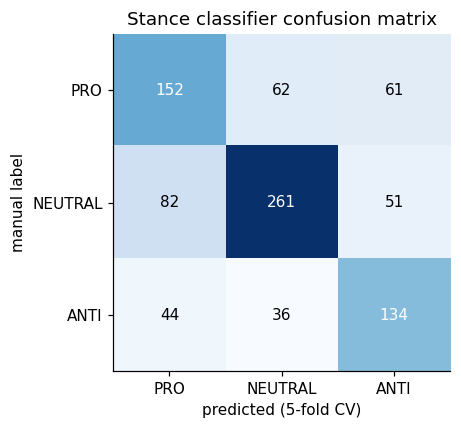

table saved: outputs/tables/06_hostility_evaluation.csv  (3 rows)


,method,roc_auc,f1
0,model only (CV),0.742,0.272
1,lexicon only,NaN,0.358
2,model ∪ lexicon (used),NaN,0.379


In [3]:
labels = ['PRO', 'NEUTRAL', 'ANTI']
cm = confusion_matrix(ann.stance, ann.stance_cv_pred, labels=labels)
fig, ax = plt.subplots(figsize=(4.5, 4)); im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(3)); ax.set_yticks(range(3)); ax.set_xticklabels(labels); ax.set_yticklabels(labels); ax.set_xlabel('predicted (5-fold CV)'); ax.set_ylabel('manual label'); ax.grid(False)
for i in range(3):
    for j in range(3): ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
ax.set_title('Stance classifier confusion matrix'); savefig('06_confusion_matrix'); plt.show()
# hostility model (rare class): logistic on the same features + lexicon union
HOST_RE = re.compile(r'idiot|moron|stupid|brainless|chutiya|chutiye|ch\*tiya|bhosdi|madarchod|behenchod|randi|kutte|kutta|suar|gaddar|traitor|terrorist|आतंकवादी|anti.?national|deshdrohi|goons?\b|thug|scum|parasite|vermin|pest control|crush(ed)? (the )?cockroach|kick(ed)? out|beat them|thrash|hang them|jail them all|paid protest|funded by|khalistani|pakistani sympathi|jihadi|libtard|sanghi|bhakt|andhbhakt|bootlick|chamcha|gaylord|retard|lost (her|his) mind', re.I)
ann['hostile'] = ann.hostile.astype(int)
hm = make_model(1.0)
h_cv = cross_val_predict(hm, ann.text_model, ann.hostile, cv=cv, method='predict_proba')[:, 1]
ann['hostile_model_cv'] = h_cv; ann['hostile_lex'] = ann.text_model.str.contains(HOST_RE).astype(int)
ann['hostile_union_cv'] = ((h_cv >= 0.5) | (ann.hostile_lex == 1)).astype(int)
h_eval = pd.DataFrame([{'method': 'model only (CV)', 'roc_auc': roc_auc_score(ann.hostile, h_cv), 'f1': f1_score(ann.hostile, (h_cv >= 0.5).astype(int))},
                       {'method': 'lexicon only', 'roc_auc': np.nan, 'f1': f1_score(ann.hostile, ann.hostile_lex)},
                       {'method': 'model ∪ lexicon (used)', 'roc_auc': np.nan, 'f1': f1_score(ann.hostile, ann.hostile_union_cv)}]).round(3)
save_table(h_eval, '06_hostility_evaluation'); h_eval

**What this shows:** two word + character TF-IDF models are used, one trained on the X labels for X and one trained on all labels (with the thread title as context) for Reddit; both clearly beat the keyword baseline, and the transfer check shows why one pooled model would be worse; the Reddit items are harder than the X posts because comments are short and depend on their thread, so community-level shares are more reliable than individual labels; a prior correction aligns the Reddit class shares with the random annotated sample. Errors are mostly between NEUTRAL and the two stances (reporting with an evaluative tone), rarely PRO↔ANTI. Hostility is rare, so the model is combined with an insult lexicon.

## 2. Predict every item, aggregate to users
Manual labels override predictions where available. User stance score = mean(P(PRO) − P(ANTI)) over the user's items; users are PRO / ANTI when |score| ≥ 0.15, otherwise NEUTRAL/mixed.

In [4]:
final_x = make_model(best['x']).fit(ann_x.text_model, ann_x.stance); final = make_model(best['reddit']).fit(ann.text_model, ann.stance)
hfinal = make_model(1.0).fit(ann.text_model, ann.hostile)
cls = list(final.classes_); assert list(final_x.classes_) == cls
proba = np.zeros((len(items), len(cls))); mx_ = (items.platform == 'x').values
proba[mx_] = final_x.predict_proba(items.loc[mx_, 'text_model']); proba[~mx_] = final.predict_proba(items.loc[~mx_, 'text_model'])
if USE_COMBINED:
    efinal = emb_model().fit(E_ann, ann.stance); proba[~mx_] = (proba[~mx_] + efinal.predict_proba(embed(items.loc[~mx_, 'text_model']))) / 2
# Prior matching: the Reddit annotation sample is a random draw of the corpus, so the predicted class shares on Reddit are re-weighted
# to be consistent with the annotated shares (quantification-style adjustment of the class priors); the X sample is stratified, not random,
# so X is left uncorrected.
ann_r = ann[ann.platform == 'reddit']
if len(ann_r) >= 100:
    # class weights are adjusted until the predicted (hard-label) class shares on Reddit match the annotated shares
    target = ann_r.stance.value_counts(normalize=True).reindex(cls).fillna(0).values
    m_r = (items.platform == 'reddit').values; P = proba[m_r].copy(); w = np.ones(len(cls))
    for _ in range(80):
        pred = np.bincount((P * w).argmax(1), minlength=len(cls)) / len(P)
        w *= (target / np.maximum(pred, 1e-6)) ** 0.5
    Pw = P * w; Pw = Pw / Pw.sum(1, keepdims=True); proba[m_r] = Pw
    print('Reddit class weights after prior matching:', dict(zip(cls, np.round(w, 3))))
items['stance'] = final.classes_[proba.argmax(1)]; items['stance_source'] = 'model'
calib = pd.DataFrame({'annotated sample (reddit)': ann_r.stance.value_counts(normalize=True), 'predicted before correction (reddit)': pd.Series(final.classes_[final.predict_proba(items.loc[items.platform == 'reddit', 'text_model']).argmax(1)]).value_counts(normalize=True) if len(ann_r) >= 100 else np.nan,
                      'predicted after correction (reddit)': items.loc[items.platform == 'reddit', 'stance'].value_counts(normalize=True),
                      'annotated sample (x, stratified)': ann[ann.platform == 'x'].stance.value_counts(normalize=True), 'predicted (x)': items.loc[items.platform == 'x', 'stance'].value_counts(normalize=True)}).round(3)
save_table(calib.reset_index().rename(columns={'index': 'stance'}), '06_calibration_check'); display(calib)
items['hostile'] = ((hfinal.predict_proba(items.text_model)[:, 1] >= 0.5) | items.text_model.str.contains(HOST_RE)).astype(int)
gold = ann.set_index('post_id')
m = items.post_id.isin(gold.index)
items.loc[m, 'stance'] = items.loc[m, 'post_id'].map(gold.stance); items.loc[m, 'stance_source'] = 'manual'
items.loc[m, 'hostile'] = items.loc[m, 'post_id'].map(gold.hostile).astype(int)
items['p_pro'], items['p_anti'], items['p_neu'] = proba[:, cls.index('PRO')], proba[:, cls.index('ANTI')], proba[:, cls.index('NEUTRAL')]
items['stance_score'] = items.p_pro - items.p_anti
for p in ['x', 'reddit']:
    sub = items[items.platform == p]
    save_table(sub[['post_id', 'thread_id', 'author', 'timestamp', 'stance', 'p_pro', 'p_anti', 'p_neu', 'stance_score', 'hostile', 'stance_source', 'themes', 'groups']], f'06_{p}_post_stance')
    us = sub[~sub.anonymous].groupby('author').agg(n_items=('post_id', 'size'), stance_score=('stance_score', 'mean'), share_pro=('stance', lambda s: (s == 'PRO').mean()),
                                                   share_anti=('stance', lambda s: (s == 'ANTI').mean()), hostile_share=('hostile', 'mean')).reset_index()
    us['user_stance'] = np.select([us.stance_score >= 0.15, us.stance_score <= -0.15], ['PRO', 'ANTI'], 'NEUTRAL')
    save_table(us, f'06_{p}_user_stance')
    print(p, 'items:', sub.stance.value_counts(normalize=True).round(3).to_dict(), '| users:', us.user_stance.value_counts().to_dict(), '| hostile items:', int(sub.hostile.sum()))

embedded 152294 new texts (cache 154541)


Reddit class weights after prior matching: {'ANTI': np.float64(1.058), 'NEUTRAL': np.float64(1.26), 'PRO': np.float64(0.723)}


table saved: outputs/tables/06_calibration_check.csv  (3 rows)


,annotated sample (reddit),predicted before correction (reddit),predicted after correction (reddit),"annotated sample (x, stratified)",predicted (x)
ANTI,0.176,0.077,0.176,0.332,0.346
NEUTRAL,0.489,0.411,0.489,0.388,0.448
PRO,0.335,0.511,0.335,0.279,0.206


table saved: outputs/tables/06_x_post_stance.csv  (1727 rows)
table saved: outputs/tables/06_x_user_stance.csv  (651 rows)
x items: {'NEUTRAL': 0.448, 'ANTI': 0.346, 'PRO': 0.206} | users: {'NEUTRAL': 264, 'ANTI': 259, 'PRO': 128} | hostile items: 106


table saved: outputs/tables/06_reddit_post_stance.csv  (161485 rows)


table saved: outputs/tables/06_reddit_user_stance.csv  (50211 rows)
reddit items: {'NEUTRAL': 0.489, 'PRO': 0.335, 'ANTI': 0.175} | users: {'NEUTRAL': 21882, 'PRO': 20548, 'ANTI': 7781} | hostile items: 27164


## 3. Community profiles: stance, themes, terms, factors

In [5]:
STOP = set('''the a an and or of to in on for is are was were be been it its this that these those with as at by from he she they we you i me my our your his her their them us
not no but if so than then there here what which who whom when where why how all any some more most such very can will would should could just also about into over under
out up down off only own same too s t don ve ll re d m https http co amp com www html via rt is se ka ki ke ko me ne se par aur ye yeh wo woh hai hain tha the thi ho hum
है हैं के की का को में से और पर ये यह वो वह भी नहीं तो ही हो था थे थी कर कि जो एक इस उस ने हम आप या अब तक लिए साथ गया गयी गए रहा रहे रही वाले वाला वाली कुछ बहुत कोई सब जब तब फिर क्या क्यों
cockroach cockroaches janta janata party cjp jantar mantar protest protests delhi india abhijeet dipke r u deleted removed'''.split())
def top_terms(texts_by_comm, n=12):
    vec = TfidfVectorizer(analyzer='word', ngram_range=(1, 2), min_df=2, max_df=0.8, sublinear_tf=True, token_pattern=r'(?u)\b[^\W\d_]{3,}\b')
    docs = [' '.join(t) for t in texts_by_comm.values()]
    if len(docs) < 2: return {}
    Xm = vec.fit_transform(docs); vocab = np.array(vec.get_feature_names_out())
    out = {}
    for i, c in enumerate(texts_by_comm.keys()):
        row = Xm[i].toarray().ravel(); idx = [j for j in row.argsort()[::-1] if vocab[j] not in STOP and not any(w in STOP for w in vocab[j].split())][:n]
        out[c] = ', '.join(vocab[idx])
    return out
profiles, themes_tabs = {}, {}
for p in ['x', 'reddit']:
    mem = load_membership(p); mem = mem[mem.is_major.astype(str).str.lower().eq('true')]
    comm = dict(zip(mem.node, mem.community))
    sub = items[(items.platform == p) & items.author.isin(comm)].copy(); sub['community'] = sub.author.map(comm)
    us = pd.read_csv(TABLES / f'06_{p}_user_stance.csv'); ustance = dict(zip(us.author, us.user_stance))
    mem['user_stance'] = mem.node.map(ustance).fillna('no_posts')
    tt = top_terms({c: g.text_model.tolist() for c, g in sub.groupby('community')})
    th = sub.assign(t=sub.themes.str.split(',')).explode('t'); th = th[th.t != '']
    theme_share = (th.groupby(['community', 't']).post_id.nunique().unstack(fill_value=0).div(sub.groupby('community').size(), axis=0).fillna(0).round(3)) if len(th) else pd.DataFrame()
    overall_share = th.groupby('t').post_id.nunique() / max(len(sub), 1)
    themes_tabs[p] = theme_share; save_table(theme_share.reset_index(), f'06_{p}_community_themes')
    rows = []
    for c, g in mem.groupby('community'):
        si = sub[sub.community == c]
        st = si.stance.value_counts(normalize=True); ust = g.user_stance.value_counts(normalize=True)
        comp = g.attribute.value_counts(normalize=True)
        dom = si.domains.str.split(',').explode(); dom = dom[(dom != '') & ~dom.isin(['x.com', 'twitter.com', 'reddit.com', 'i.redd.it', 'v.redd.it'])].value_counts().head(3)
        tags = si.hashtags.str.split(',').explode() if p == 'x' else si.subreddit
        tags = tags[tags != ''].value_counts().head(4)
        if len(theme_share) and c in theme_share.index:
            row_t = theme_share.loc[c]; cand = row_t[row_t >= 0.10]
            main_theme = (cand / overall_share.reindex(cand.index).replace(0, np.nan)).idxmax() if len(cand) else row_t.idxmax()
        else: main_theme = ''
        pro, anti, neu = st.get('PRO', 0), st.get('ANTI', 0), st.get('NEUTRAL', 0)
        news = comp.get('news_media', 0)
        upro, uanti = ust.get('PRO', 0), ust.get('ANTI', 0)
        stance_label = ('Pro-protest' if (pro >= 0.4 and pro >= anti * 1.5) or (upro >= 0.4 and upro >= uanti * 1.5)
                        else 'Anti-CJP / pro-government' if (anti >= 0.4 and anti >= pro * 1.5) or (uanti >= 0.4 and uanti >= upro * 1.5)
                        else 'News / reporting' if (news >= 0.4 and neu >= 0.5) else 'Mixed / contested')
        rows.append({'community': c, 'users': len(g), 'users_with_posts': int((g.user_stance != 'no_posts').sum()), 'items': len(si),
                     'stance_PRO_%': round(100 * pro, 1), 'stance_ANTI_%': round(100 * anti, 1), 'stance_NEUTRAL_%': round(100 * neu, 1),
                     'users_PRO': int(ust.get('PRO', 0) * (g.user_stance != 'no_posts').sum()), 'users_ANTI': int(ust.get('ANTI', 0) * (g.user_stance != 'no_posts').sum()),
                     'hostile_%': round(100 * si.hostile.mean(), 1) if len(si) else np.nan, 'main_theme': main_theme,
                     'top_terms': tt.get(c, ''), 'top_hashtags_or_subreddits': ', '.join(f'{k} ({v})' for k, v in tags.items()),
                     'shared_sources': ', '.join(f'{k} ({v})' for k, v in dom.items()), 'composition': '; '.join(f'{k} {v*100:.0f}%' for k, v in comp.head(3).items()),
                     'top_hubs': ', '.join(g.sort_values('weighted_in', ascending=False).node.head(3)), 'stance_label': stance_label,
                     'label': f"{stance_label} · {main_theme.replace('_', ' ')}" if main_theme else stance_label})
    prof = pd.DataFrame(rows).sort_values('users', ascending=False); profiles[p] = prof
    save_table(prof, f'06_{p}_community_profile')
    # representative posts: 3 most engaged + 2 random per community, with their stance
    reps = []
    for c, si in sub.groupby('community'):
        si = si[si.text_model.str.len() > 40]
        if len(si) == 0: continue
        pick = pd.concat([si.sort_values('likes', ascending=False).head(3), si.sample(min(2, len(si)), random_state=1)]).drop_duplicates('post_id')
        reps.append(pick.assign(community=c)[['community', 'post_id', 'author', 'timestamp', 'stance', 'stance_source', 'likes', 'text_model']])
    save_table(pd.concat(reps), f'06_{p}_representative_posts')
pd.set_option('display.max_colwidth', 80)
display(profiles['x'][['community', 'users', 'items', 'stance_PRO_%', 'stance_ANTI_%', 'stance_NEUTRAL_%', 'hostile_%', 'main_theme', 'composition', 'top_hubs', 'label']])
display(profiles['reddit'][['community', 'users', 'items', 'stance_PRO_%', 'stance_ANTI_%', 'stance_NEUTRAL_%', 'hostile_%', 'main_theme', 'top_hashtags_or_subreddits', 'top_hubs', 'label']])

table saved: outputs/tables/06_x_community_themes.csv  (14 rows)
table saved: outputs/tables/06_x_community_profile.csv  (14 rows)
table saved: outputs/tables/06_x_representative_posts.csv  (67 rows)


table saved: outputs/tables/06_reddit_community_themes.csv  (15 rows)
table saved: outputs/tables/06_reddit_community_profile.csv  (15 rows)
table saved: outputs/tables/06_reddit_representative_posts.csv  (75 rows)


,community,users,items,stance_PRO_%,stance_ANTI_%,stance_NEUTRAL_%,hostile_%,main_theme,composition,top_hubs,label
0,1,57,185,48.6,17.3,34.1,1.6,media_coverage,citizen_other 37%; news_media 32%; politician_party 12%,"cockroachisback, wangchuk66, sauravdassss",Pro-protest · media coverage
1,2,53,209,27.3,44.0,28.7,8.6,minister_accountability,citizen_other 43%; news_media 23%; other 13%,"abhijeet_dipke, newsarenaindia, elvishyadav",Anti-CJP / pro-government · minister accountability
2,3,37,37,29.7,37.8,32.4,10.8,opposition_politics,other 57%; citizen_other 16%; news_media 11%,"ani, arvindkejriwal, aamaadmiparty",Mixed / contested · opposition politics
3,4,35,115,10.4,57.4,32.2,8.7,police_repression,other 43%; news_media 23%; citizen_other 14%,"delhipolice, narendramodi, cpdelhi",Anti-CJP / pro-government · police repression
4,5,24,33,9.1,24.2,66.7,6.1,conspiracy_funding,other 62%; news_media 21%; public_figure 8%,"ians_india, ddnewslive, dtptraffic",Mixed / contested · conspiracy funding
5,6,19,28,0.0,0.0,100.0,0.0,satire_cji_remark,other 53%; citizen_other 37%; ai_bot 5%,"grok, factcheckpulse, phdwaala",Mixed / contested · satire cji remark
6,7,15,66,22.7,6.1,71.2,3.0,wangchuk_fast,other 47%; news_media 40%; cjp_org 7%,"cjp_for_india, uddhavthackeray, cockroach4india",News / reporting · wangchuk fast
7,8,14,8,12.5,25.0,62.5,0.0,satire_cji_remark,other 43%; citizen_other 36%; news_media 21%,"cjp_2029, dpradhanbjp, eduminofindia",Mixed / contested · satire cji remark
8,9,12,53,15.1,9.4,75.5,1.9,wangchuk_fast,other 67%; news_media 25%; citizen_other 8%,"sushil_verma9, vijaita, shashiskashyap",Mixed / contested · wangchuk fast
9,10,11,5,0.0,40.0,60.0,0.0,satire_cji_remark,other 73%; partisan_citizen 18%; news_media 9%,"uppolice, dgpup, bjp4up",Anti-CJP / pro-government · satire cji remark


,community,users,items,stance_PRO_%,stance_ANTI_%,stance_NEUTRAL_%,hostile_%,main_theme,top_hashtags_or_subreddits,top_hubs,label
0,1,2166,6752,32.0,15.3,52.8,15.2,government_bjp,"india (3352), unitedstatesofindia (619), delhi (283), indiameme (280)","good-preparation200, littleartsy, theshinchanfan778",Pro-protest · government bjp
1,2,1984,4864,37.9,20.7,41.4,23.7,government_bjp,"Kolkatacity (918), indiadiscussion (729), Whysooserious (553), unfilteredind...","dear-time5236, landexpensive2108, national-mammoth-151",Pro-protest · government bjp
2,3,1548,7804,30.5,23.9,45.6,15.7,government_bjp,"IndiaSpeaks (2545), indiadiscussion (955), CriticalThinkingIndia (536), NewD...","any-calligrapher2866, exporinglife2050, emeron87",Mixed / contested · government bjp
3,4,1411,3561,24.5,17.9,57.5,13.6,students_youth,"InstaCelebsGossip (1367), TeenIndia (424), TwentiesIndia (300), india (147)","doctorr__doom, dragondeninsharktank, yogi10997",Mixed / contested · students youth
4,5,1334,4157,29.5,17.4,53.2,20.4,police_repression,"IndianFocus (1510), CriticalThinkingIndia (406), IndiaTodayLIVE (384), india...","futureversion812, indiatoday, nice-buddy6502",Mixed / contested · police repression
5,6,1315,2852,45.9,14.7,39.3,18.1,wangchuk_fast,"IndianFocus (716), TheBetterIndia (390), IndiaTech (242), indiameme (178)","mumanworld, aryan_jandyal, recently_4live",Pro-protest · wangchuk fast
6,7,1089,4102,29.2,19.7,51.1,16.3,students_youth,"CriticalThinkingIndia (1813), indiameme (164), IndianFocus (159), indiadiscu...","superbhealth5023, givemesomesunshine3, godkiller__",Mixed / contested · students youth
7,8,985,2785,33.2,15.4,51.4,15.1,wangchuk_fast,"CriticalThinkingIndia (1370), india (301), indiadiscussion (152), IndianFocu...","competitive-joke9510, quiet_form_2800, groundbreakingbad183",Pro-protest · wangchuk fast
8,9,934,2113,24.2,10.2,65.6,5.3,government_bjp,"AskTheWorld (1693), teenagers (68), PahadiTalks (47), worldnews (29)","greedy-two9043, tempest4674, cartographer_69_",Mixed / contested · government bjp
9,10,906,3513,34.8,24.7,40.4,26.2,police_repression,"RealTeensIndia (602), indiadiscussion (420), Kolkatacity (271), Dhurandhar (...","immediate-humor-6077, functionwild5635, infamous_draw_993",Mixed / contested · police repression


figure saved: outputs/figures/06_community_stance.png


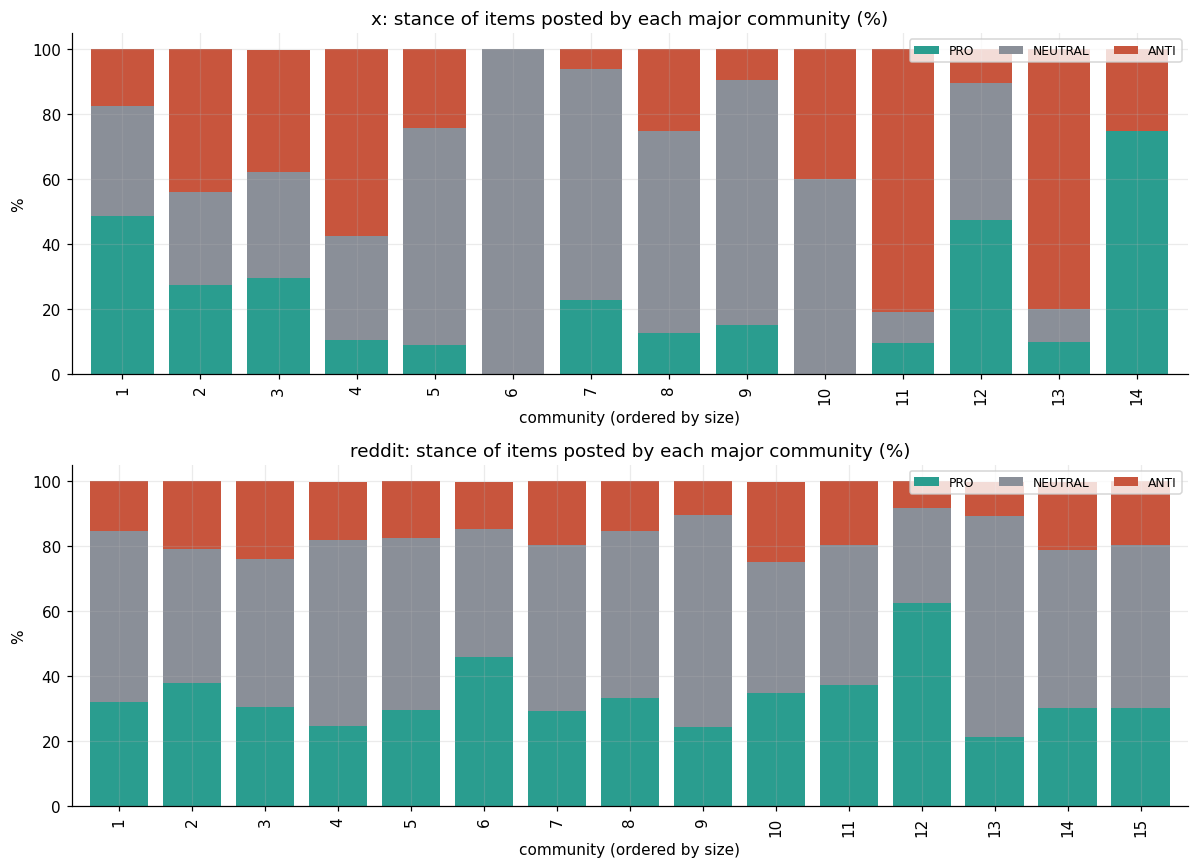

figure saved: outputs/figures/06_theme_heatmap.png


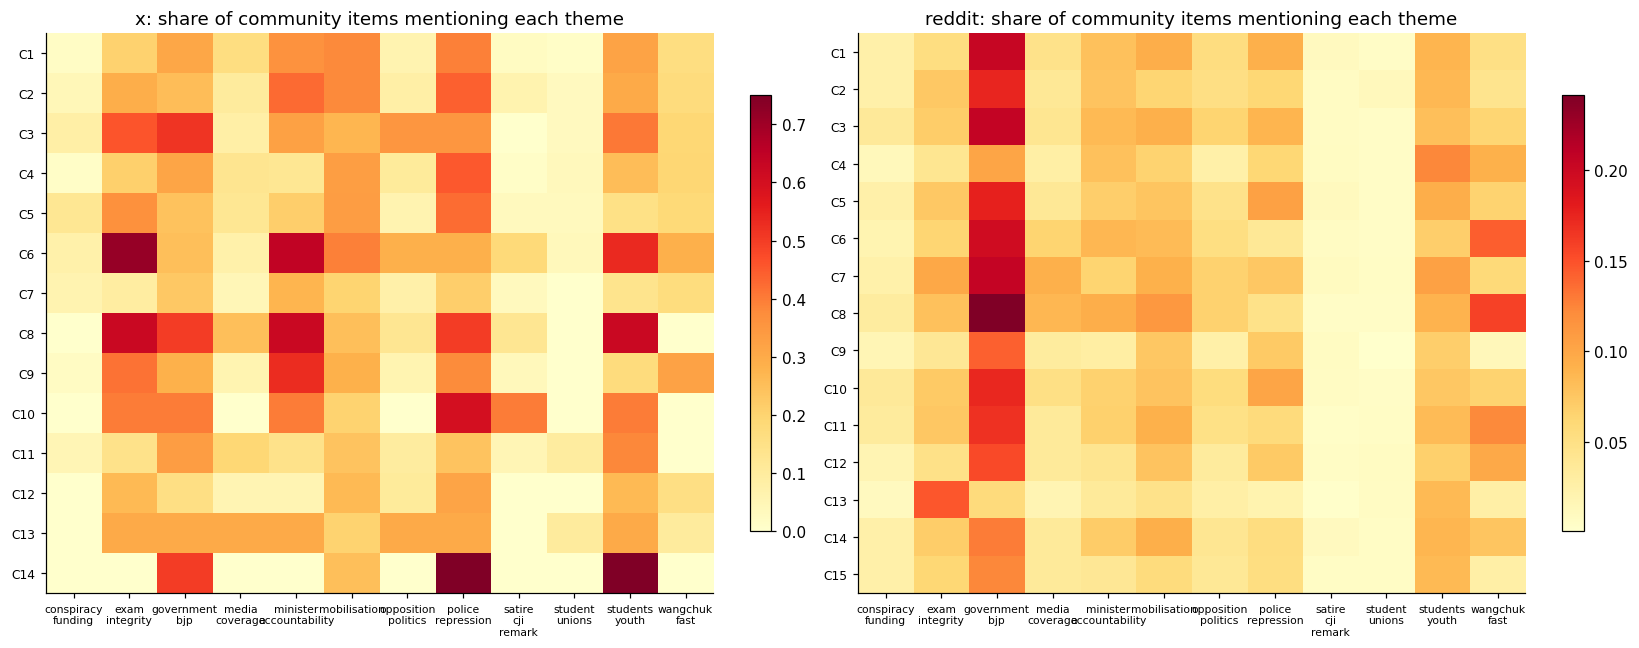

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(11, 8))
for ax, p in zip(axes, ['x', 'reddit']):
    pr = profiles[p].set_index('community')[['stance_PRO_%', 'stance_NEUTRAL_%', 'stance_ANTI_%']]
    pr.plot.bar(ax=ax, stacked=True, color=[PALETTE['PRO'], PALETTE['NEUTRAL'], PALETTE['ANTI']], width=0.8)
    ax.set_title(f'{p}: stance of items posted by each major community (%)'); ax.set_ylabel('%'); ax.set_xlabel('community (ordered by size)'); ax.legend(['PRO', 'NEUTRAL', 'ANTI'], ncol=3, fontsize=8)
savefig('06_community_stance'); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, p in zip(axes, ['x', 'reddit']):
    th = themes_tabs[p]
    if len(th):
        th = th.loc[profiles[p].community.tolist()] if set(profiles[p].community) <= set(th.index) else th
        im = ax.imshow(th.values, cmap='YlOrRd', aspect='auto'); ax.set_xticks(range(th.shape[1])); ax.set_xticklabels([c.replace('_', '\n') for c in th.columns], fontsize=7); ax.set_yticks(range(th.shape[0])); ax.set_yticklabels([f'C{c}' for c in th.index], fontsize=8)
        ax.set_title(f'{p}: share of community items mentioning each theme'); ax.grid(False); plt.colorbar(im, ax=ax, fraction=0.03)
savefig('06_theme_heatmap'); plt.show()

**What this shows:** communities differ sharply in stance: on X the clusters around the CJP accounts and opposition politicians are predominantly PRO, the clusters around partisan accounts, Delhi Police and right-leaning media are ANTI, and the news-media clusters are mostly NEUTRAL. Themes are more uniform (exam integrity and the minister's resignation everywhere), with police repression and the conspiracy/funding frame concentrated in specific communities.

## 4. Validation of the labels
Manual labels inside each community versus the classifier's out-of-fold predictions, and a sample sheet for the team to check by hand.

In [7]:
val = []
for p in ['x', 'reddit']:
    mem = load_membership(p); comm = dict(zip(mem.node, mem.community))
    a = ann[ann.platform == p].copy(); a['community'] = a.post_id.map(dict(zip(items.post_id, items.author))).map(comm)
    for c, g in a.dropna(subset=['community']).groupby('community'):
        if len(g) >= 5: val.append({'platform': p, 'community': int(c), 'annotated_items': len(g), 'cv_accuracy': round(accuracy_score(g.stance, g.stance_cv_pred), 3), 'manual_PRO': int((g.stance == 'PRO').sum()), 'manual_ANTI': int((g.stance == 'ANTI').sum())})
val = pd.DataFrame(val); save_table(val, '06_validation_by_community')
check = items[items.stance_source == 'model'].groupby('platform', group_keys=False).apply(lambda d: d.sample(min(40, len(d)), random_state=3))
save_table(check[['platform', 'post_id', 'author', 'stance', 'p_pro', 'p_anti', 'hostile', 'text_model']].assign(manual_check=''), '06_manual_check_sheet')
val

table saved: outputs/tables/06_validation_by_community.csv  (37 rows)
table saved: outputs/tables/06_manual_check_sheet.csv  (80 rows)


,platform,community,annotated_items,cv_accuracy,manual_PRO,manual_ANTI
0,x,1,52,0.692,32,6
1,x,2,71,0.761,29,29
2,x,3,11,0.818,5,3
3,x,4,20,0.600,0,12
4,x,5,8,0.875,2,0
5,x,6,26,0.923,0,0
6,x,7,7,0.857,4,0
7,x,11,7,0.857,0,7
8,x,16,7,0.714,0,7
9,x,17,11,1.000,0,0
